In [6]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Libraries imported successfully!")


Libraries imported successfully!


In [8]:

df = pd.read_csv("most_used_beauty_cosmetics_products_extended.csv")

print("Dataset shape:", df.shape)
print("\nDataset columns:")
print(df.columns.tolist())

print("\nFirst five rows:")
display(df.head())

print("\nMissing values:")
display(df.isnull().sum())


Dataset shape: (15000, 14)

Dataset columns:
['Product_Name', 'Brand', 'Category', 'Usage_Frequency', 'Price_USD', 'Rating', 'Number_of_Reviews', 'Product_Size', 'Skin_Type', 'Gender_Target', 'Packaging_Type', 'Main_Ingredient', 'Cruelty_Free', 'Country_of_Origin']

First five rows:


,Product_Name,Brand,Category,Usage_Frequency,Price_USD,Rating,Number_of_Reviews,Product_Size,Skin_Type,Gender_Target,Packaging_Type,Main_Ingredient,Cruelty_Free,Country_of_Origin
0,Ultra Face Mask,Drunk Elephant,Blush,Weekly,67.85,1.4,686,30ml,Sensitive,Female,Tube,Retinol,False,Australia
1,Ultra Lipstick,Laura Mercier,Makeup Remover,Occasional,116.43,4.2,5483,250ml,Dry,Unisex,Bottle,Shea Butter,False,UK
2,Ultra Serum,Natasha Denona,Highlighter,Daily,90.84,1.6,5039,100ml,Sensitive,Male,Compact,Aloe Vera,True,Italy
3,Divine Serum,Ilia Beauty,Face Mask,Occasional,55.17,3.2,6202,250ml,Normal,Male,Tube,Glycerin,True,South Korea
4,Super Foundation,Charlotte Tilbury,Highlighter,Occasional,140.56,1.7,297,100ml,Oily,Female,Compact,Glycerin,False,Germany



Missing values:


Product_Name         0
Brand                0
Category             0
Usage_Frequency      0
Price_USD            0
Rating               0
Number_of_Reviews    0
Product_Size         0
Skin_Type            0
Gender_Target        0
Packaging_Type       0
Main_Ingredient      0
Cruelty_Free         0
Country_of_Origin    0
dtype: int64

In [9]:
TARGET_COLUMN = "Rating"

if TARGET_COLUMN not in df.columns:
    raise ValueError("The dataset must contain a 'Rating' column.")

df[TARGET_COLUMN] = pd.to_numeric(df[TARGET_COLUMN], errors="coerce")
df = df.dropna(subset=[TARGET_COLUMN]).copy()

drop_cols = [TARGET_COLUMN]
if "Product_Name" in df.columns:
    drop_cols.append("Product_Name")

X = df.drop(columns=drop_cols).copy()
y = df[TARGET_COLUMN].copy()
 
X = X.dropna(axis=1, how="all")

numeric_features = X.select_dtypes(
    include=["number", "bool"]
).columns.tolist()

categorical_features = [
    col for col in X.columns
    if col not in numeric_features
]


numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

 
try:
    encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=True)
except TypeError:
    encoder = OneHotEncoder(handle_unknown="ignore", sparse=True)

 
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", encoder)
])

transformers = []

if numeric_features:
    transformers.append(
        ("numeric", numeric_pipeline, numeric_features)
    )

if categorical_features:
    transformers.append(
        ("categorical", categorical_pipeline, categorical_features)
    )

preprocessor = ColumnTransformer(transformers=transformers)

 
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

 
models = {
    "Mean Baseline": DummyRegressor(strategy="mean"),
    "Ridge Regression": Ridge(alpha=1.0),
    "Decision Tree": DecisionTreeRegressor(
        max_depth=8,
        min_samples_leaf=3,
        random_state=42
    ),
    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    )
}
 
cv = KFold(n_splits=5, shuffle=True, random_state=42)

rows = []
prediction_frames = []
fitted_models = {}

for name, estimator in models.items():

    pipeline = Pipeline([
        ("preprocess", preprocessor),
        ("model", estimator)
    ])

    cv_result = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "mae": "neg_mean_absolute_error",
            "rmse": "neg_root_mean_squared_error",
            "r2": "r2"
        },
        error_score="raise"
    )

    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)
    fitted_models[name] = pipeline

    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    rows.append({
        "Model": name,
        "Test MAE": mae,
        "Test RMSE": rmse,
        "Test R2": r2,
        "CV MAE Mean": -cv_result["test_mae"].mean(),
        "CV MAE Std": cv_result["test_mae"].std(),
        "CV RMSE Mean": -cv_result["test_rmse"].mean(),
        "CV R2 Mean": cv_result["test_r2"].mean()
    })

    prediction_frames.append(pd.DataFrame({
        "Actual Rating": y_test.to_numpy(),
        "Predicted Rating": predictions,
        "Model": name
    }))

results = pd.DataFrame(rows)
results = results.sort_values("Test MAE").reset_index(drop=True)

print("MODEL EVALUATION RESULTS")
display(results.round(4))

print("Best model by test MAE:", results.loc[0, "Model"])


MODEL EVALUATION RESULTS


,Model,Test MAE,Test RMSE,Test R2,CV MAE Mean,CV MAE Std,CV RMSE Mean,CV R2 Mean
0,Mean Baseline,1.0228,1.1721,-0.0006,1.0116,0.0117,1.1669,-0.0000
1,Ridge Regression,1.0257,1.1774,-0.0096,1.0159,0.0133,1.1742,-0.0126
2,Random Forest,1.0328,1.1901,-0.0314,1.0211,0.0130,1.1837,-0.0290
3,Decision Tree,1.0375,1.1990,-0.0469,1.0285,0.0144,1.1958,-0.0501


Best model by test MAE: Mean Baseline


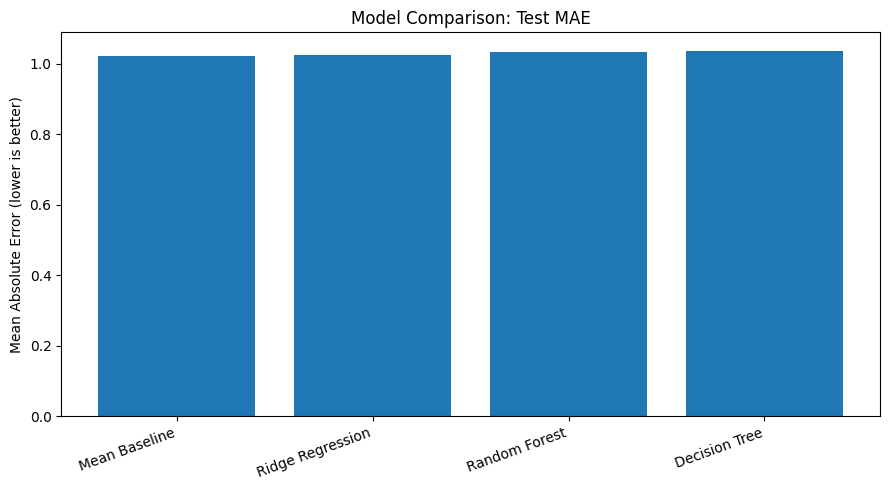

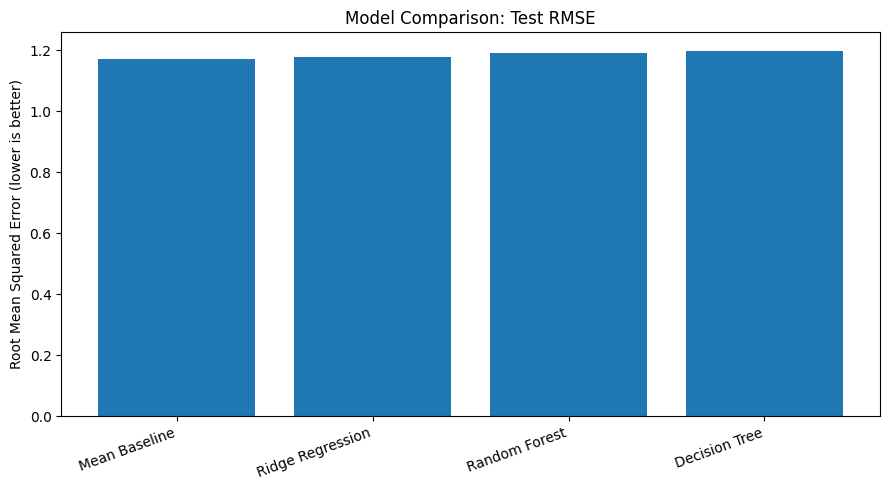

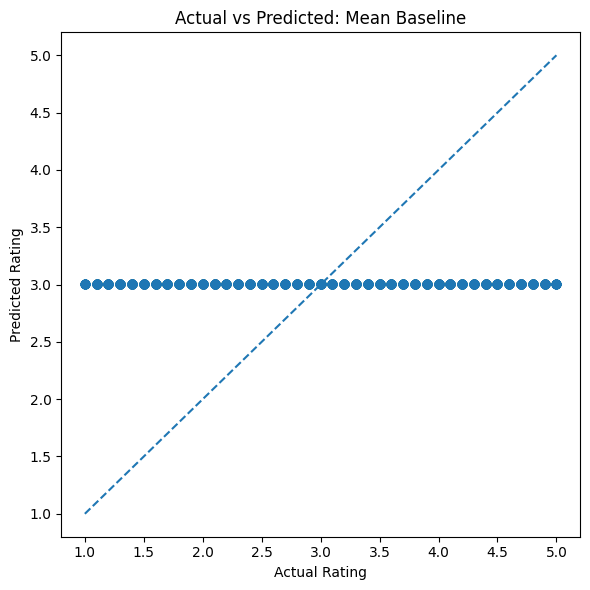

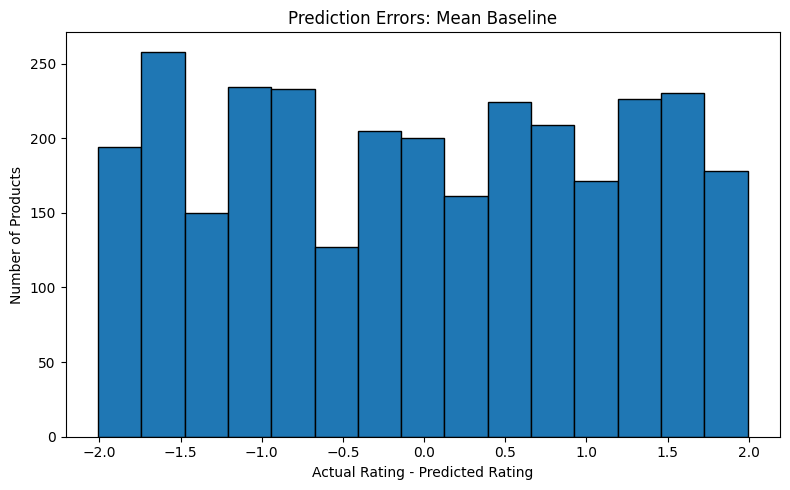


WEEK 6 MODEL EVALUATION SUMMARY

Dataset rows evaluated: 15000
Target column: Rating
Training rows: 12000
Testing rows: 3000

Best model by test MAE: Mean Baseline
Test MAE: 1.0228
Test RMSE: 1.1721
Test R-squared: -0.0006
Cross-validation MAE mean: 1.0116

MAE measures average absolute prediction error in rating points.
RMSE penalizes larger errors more strongly.
R-squared measures performance relative to a mean-based reference.

These models predict product ratings, not sales or revenue.
The results show patterns and predictive performance, not causation.

All results and charts saved in the outputs_week6 folder.


In [10]:

os.makedirs("outputs_week6", exist_ok=True)

# Save evaluation results
results.to_csv(
    "outputs_week6/model_evaluation_results.csv",
    index=False
)

all_predictions = pd.concat(
    prediction_frames,
    ignore_index=True
)

all_predictions.to_csv(
    "outputs_week6/test_set_predictions.csv",
    index=False
)

# Chart 1: Compare MAE
plt.figure(figsize=(9, 5))
plt.bar(results["Model"], results["Test MAE"])
plt.title("Model Comparison: Test MAE")
plt.ylabel("Mean Absolute Error (lower is better)")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.savefig("outputs_week6/test_mae_comparison.png", dpi=150)
plt.show()

# Chart 2: Compare RMSE
rmse_results = results.sort_values("Test RMSE")

plt.figure(figsize=(9, 5))
plt.bar(rmse_results["Model"], rmse_results["Test RMSE"])
plt.title("Model Comparison: Test RMSE")
plt.ylabel("Root Mean Squared Error (lower is better)")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.savefig("outputs_week6/test_rmse_comparison.png", dpi=150)
plt.show()

# Chart 3: Actual versus predicted ratings for best MAE model
best_model_name = results.loc[0, "Model"]

best_predictions = all_predictions[
    all_predictions["Model"] == best_model_name
]

plt.figure(figsize=(6, 6))
plt.scatter(
    best_predictions["Actual Rating"],
    best_predictions["Predicted Rating"],
    alpha=0.7
)

low = min(
    best_predictions["Actual Rating"].min(),
    best_predictions["Predicted Rating"].min()
)

high = max(
    best_predictions["Actual Rating"].max(),
    best_predictions["Predicted Rating"].max()
)

plt.plot([low, high], [low, high], "--")
plt.xlabel("Actual Rating")
plt.ylabel("Predicted Rating")
plt.title(f"Actual vs Predicted: {best_model_name}")
plt.tight_layout()
plt.savefig(
    "outputs_week6/actual_vs_predicted_best_model.png",
    dpi=150
)
plt.show()

# Chart 4: Prediction error distribution
residuals = (
    best_predictions["Actual Rating"]
    - best_predictions["Predicted Rating"]
)

plt.figure(figsize=(8, 5))
plt.hist(residuals, bins=15, edgecolor="black")
plt.title(f"Prediction Errors: {best_model_name}")
plt.xlabel("Actual Rating - Predicted Rating")
plt.ylabel("Number of Products")
plt.tight_layout()
plt.savefig(
    "outputs_week6/residual_distribution_best_model.png",
    dpi=150
)
plt.show()

# Save a summary based on actual results
best = results.iloc[0]

summary = f"""
WEEK 6 MODEL EVALUATION SUMMARY

Dataset rows evaluated: {len(df)}
Target column: Rating
Training rows: {len(X_train)}
Testing rows: {len(X_test)}

Best model by test MAE: {best['Model']}
Test MAE: {best['Test MAE']:.4f}
Test RMSE: {best['Test RMSE']:.4f}
Test R-squared: {best['Test R2']:.4f}
Cross-validation MAE mean: {best['CV MAE Mean']:.4f}

MAE measures average absolute prediction error in rating points.
RMSE penalizes larger errors more strongly.
R-squared measures performance relative to a mean-based reference.

These models predict product ratings, not sales or revenue.
The results show patterns and predictive performance, not causation.
"""

with open(
    "outputs_week6/evaluation_summary.txt",
    "w",
    encoding="utf-8"
) as file:
    file.write(summary)

print(summary)
print("All results and charts saved in the outputs_week6 folder.")
